# Universidad Politécnica Salesiana
## Ingeniería en Computación
### Inteligencia Artificial
### Práctica 03 – El Perceptrón

**Integrantes:**
- Mauricio Jácome
- Ismael Cornejo


## Introducción

En esta práctica trabajamos con un perceptrón, que es un modelo sencillo de clasificación binaria. Su función es aprender a separar dos grupos de puntos mediante una línea. Para comprender cómo funciona, vamos a programar los cálculos y la actualización de los pesos por nuestra cuenta, sin usar librerías de aprendizaje automático. También observaremos cómo cambia la línea durante el entrenamiento y qué pasa cuando modificamos la tasa de aprendizaje.

## Objetivos

- Comprender cómo se utiliza un perceptrón para clasificar datos en dos grupos.
- Implementar la inicialización de pesos, la función de activación y el aprendizaje del modelo.
- Representar gráficamente la frontera de decisión antes y después de entrenar.
- Probar el perceptrón con puntos que no se utilizaron durante el entrenamiento.
- Comparar las tasas de aprendizaje 0.3, 0.5 y 0.8.

## Herramientas utilizadas

Usamos **Python en Google Colab**. Para los cálculos del perceptrón trabajamos con listas, ciclos, condicionales y operaciones aritméticas. `random` se utiliza únicamente para los pesos iniciales y `matplotlib` para las gráficas. No utilizamos `scikit-learn` ni otras librerías de *machine learning*.

## Verificación de librerías

Importamos únicamente las librerías necesarias. Fijamos una semilla para que los pesos iniciales y los resultados sean reproducibles.

In [1]:
import random
import matplotlib.pyplot as plt

random.seed(42)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


---
## Fase 1. Exploración del Dataset

### Actividad 1.a — Inspección inicial

Creamos la matriz `X` y el vector de etiquetas `y` con los 23 puntos de la guía. Después contamos las instancias, las variables de entrada y las clases, sin librerías para analizar datos.

In [2]:
# Dataset de la guía: primero la clase -1 y después la clase +1
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2],
    [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9],
    [12, 6], [14, 7], [16, 4]
]
y = [-1] * 14 + [1] * 9

n_total = len(X)
n_variables = len(X[0])
clases = []
conteo_negativos = 0
conteo_positivos = 0

for etiqueta in y:
    if etiqueta not in clases:
        clases.append(etiqueta)
    if etiqueta == -1:
        conteo_negativos += 1
    else:
        conteo_positivos += 1

print("Número total de instancias:", n_total)
print("Variables de entrada:", n_variables, "(x1 y x2)")
print("Número de clases:", len(clases))
print("Puntos de la clase -1:", conteo_negativos)
print("Puntos de la clase +1:", conteo_positivos)

Número total de instancias: 23
Variables de entrada: 2 (x1 y x2)
Número de clases: 2
Puntos de la clase -1: 14
Puntos de la clase +1: 9


**Pregunta guía: ¿Qué representa cada fila de `X`? ¿Qué representa cada valor de `y`? ¿Por qué es clasificación binaria?**

Cada fila de `X` representa un punto con dos valores: `x1` y `x2`. En `y` se guarda la clase a la que pertenece ese punto. Es un problema de clasificación binaria porque solo tenemos dos posibles clases, **-1 y +1**. En total contamos **23 puntos: 14 de la clase -1 y 9 de la clase +1**.

### Actividad 1.b — Separación visual de las clases

Creamos una función para mostrar los puntos con símbolos diferentes y poder observar si parecen separables mediante una recta.

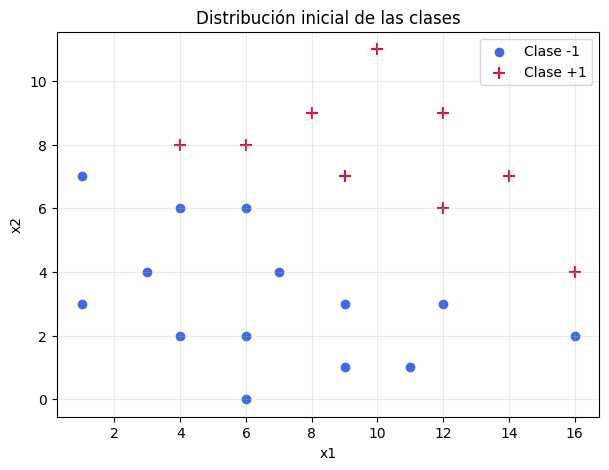

In [3]:
def plot_dataset(X, y, title):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    plt.figure(figsize=(7, 5))
    plt.scatter(x1_neg, x2_neg, color="royalblue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="crimson", marker="+", s=85, label="Clase +1")
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

plot_dataset(X, y, "Distribución inicial de las clases")

**Pregunta guía: Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta?**

Sí. Al ver los puntos, la clase +1 se encuentra en general por encima de la clase -1. Aunque están distribuidos en diferentes posiciones, parece posible dibujar una recta inclinada que los separe. Más adelante comprobaremos si el perceptrón logra encontrarla.

### Resultados de la fase 1

El dataset contiene **23 puntos** y **dos variables de entrada**. De ellos, **14 corresponden a la clase -1** y **9 a la clase +1**. La gráfica inicial permite observar que ambas clases parecen separables con una recta inclinada.

---
## Fase 2. Fundamento del Perceptrón

El perceptrón calcula una suma ponderada y después determina a qué clase corresponde cada punto. En este ejercicio usamos la fórmula:

\[
z = w_0 + w_1x_1 + w_2x_2
\]

La función de activación devuelve **+1** cuando `z` es mayor o igual a cero y **-1** cuando es menor que cero.

### Actividad 2.a — Vector de pesos

Creamos la función `initialize_weights()` para generar tres pesos aleatorios entre -0.5 y 0.5.

In [4]:
def initialize_weights():
    return [random.uniform(-0.5, 0.5) for i in range(3)]

pesos_prueba = initialize_weights()
print("Pesos iniciales de prueba:", pesos_prueba)

Pesos iniciales de prueba: [0.13942679845788375, -0.47498924477733306, -0.22497068163088074]


**Pregunta guía: ¿Por qué hay tres pesos si tenemos dos variables? ¿Qué función cumple el bias?**

Tenemos dos pesos para las entradas `x1` y `x2` y un tercer valor, `w0`, que es el **bias**. El bias permite mover la frontera de decisión sin depender solamente de los valores de entrada. Gracias a eso, la recta no tiene que pasar obligatoriamente por el origen.

### Actividad 2.b — Función de activación

Implementamos la función escalón bipolar que transforma la suma ponderada en una de las dos etiquetas.

In [5]:
def activation(z):
    if z >= 0:
        return 1
    else:
        return -1

print("activation(2) =", activation(2))
print("activation(-3) =", activation(-3))
print("activation(0) =", activation(0))

activation(2) = 1
activation(-3) = -1
activation(0) = 1


**Pregunta guía: ¿Por qué se utilizan las etiquetas -1 y 1 en lugar de 0 y 1?**

La representación bipolar permite distinguir directamente si la salida está a un lado u otro de cero. Además, la diferencia entre el valor real y el predicho sirve para ajustar los pesos en la dirección que corresponde cuando el perceptrón se equivoca.

### Actividad 2.c — Cálculo de salida

La función recibe un solo punto `[x1, x2]` y los tres pesos. Calcula `z` y devuelve la clase mediante `activation()`. Probamos el procedimiento con tres puntos del dataset.

In [6]:
def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

for i in [0, 14, 22]:
    resultado = perceptron_compute(X[i], pesos_prueba)
    print("Punto:", X[i], "Clase real:", y[i], "Salida inicial:", resultado)

Punto: [1, 7] Clase real: -1 Salida inicial: -1
Punto: [4, 8] Clase real: 1 Salida inicial: -1
Punto: [16, 4] Clase real: 1 Salida inicial: -1


**Pregunta guía: ¿Cuál es la diferencia entre la suma ponderada `z` y la salida final? ¿Por qué no basta con calcular `z`?**

`z` es un número que resulta de combinar las entradas con sus pesos. La salida final es la clase **-1 o +1** que se obtiene después de aplicar la función de activación. Necesitamos esa salida porque nuestro objetivo es clasificar cada punto, no solo calcular un número.

### Resultados de la fase 2

Implementamos `initialize_weights()`, `activation(z)` y `perceptron_compute(x, w)`. Las pruebas con tres instancias muestran que los pesos iniciales aún no garantizan predicciones correctas; por eso necesitamos entrenar el modelo.

---
## Fase 3. Visualización de la Frontera de Decisión

La frontera es la recta donde la suma ponderada es cero:

\[
w_0 + w_1x_1 + w_2x_2 = 0
\]

Si `w2` es distinto de cero, podemos despejar `x2`. Si es cero, revisamos si podemos dibujar una recta vertical con `w1`.

### Actividad 3.a — Función de graficación

Creamos `perceptron_plot(X, y, w, title)` para mostrar los puntos y su frontera de decisión.

In [7]:
def perceptron_plot(X, y, w, title):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    x_min = min(punto[0] for punto in X) - 1
    x_max = max(punto[0] for punto in X) + 1

    plt.figure(figsize=(7, 5))
    plt.scatter(x1_neg, x2_neg, color="royalblue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="crimson", marker="+", s=85, label="Clase +1")

    if w[2] != 0:
        x_recta = [x_min, x_max]
        y_recta = [
            -(w[0] + w[1] * x_min) / w[2],
            -(w[0] + w[1] * x_max) / w[2]
        ]
        plt.plot(x_recta, y_recta, color="forestgreen", label="Frontera de decisión")
    elif w[1] != 0:
        x_vertical = -w[0] / w[1]
        plt.axvline(x_vertical, color="forestgreen", label="Frontera de decisión")
    else:
        print("Con estos pesos no existe una recta de decisión que se pueda graficar.")

    plt.xlim(x_min, x_max)
    plt.ylim(min(punto[1] for punto in X) - 1, max(punto[1] for punto in X) + 1)
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

print("Función perceptron_plot definida correctamente.")

Función perceptron_plot definida correctamente.


**Pregunta guía: ¿Qué representa geométricamente la recta? ¿Qué ocurre con pesos iniciales aleatorios?**

La recta marca la división entre las dos regiones que el perceptrón clasifica como -1 y +1. Como los pesos iniciales se escogen al azar, esa recta aparece en una posición cualquiera y todavía no ha aprendido a separar los datos.

### Actividad 3.b — Gráfica con pesos iniciales

Usamos los mismos pesos de prueba generados en la fase anterior para observar cómo empieza el modelo.

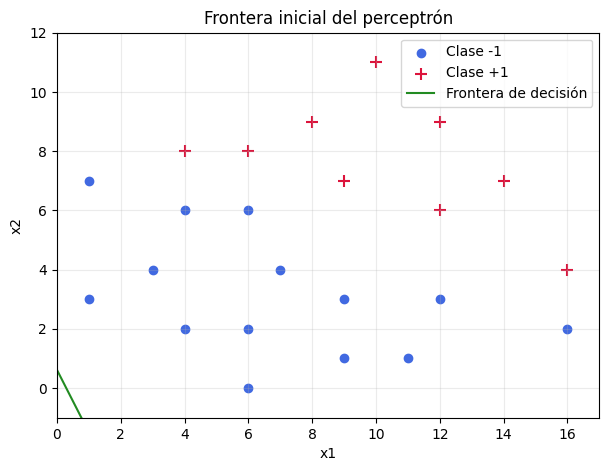

Pesos iniciales: [0.13942679845788375, -0.47498924477733306, -0.22497068163088074]
Aciertos iniciales: 14 de 23
Errores iniciales: 9


In [8]:
w_initial = pesos_prueba.copy()
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

aciertos_iniciales = 0
for i in range(len(X)):
    if perceptron_compute(X[i], w_initial) == y[i]:
        aciertos_iniciales += 1

print("Pesos iniciales:", w_initial)
print("Aciertos iniciales:", aciertos_iniciales, "de", len(X))
print("Errores iniciales:", len(X) - aciertos_iniciales)

**Pregunta guía: ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que sea correcta?**

No clasifica todos los puntos correctamente: con nuestros pesos iniciales obtiene **14 aciertos y 9 errores**. Esto ocurre porque los valores se generaron de forma aleatoria y todavía no se han corregido usando las etiquetas reales. Por eso necesitamos entrenar el perceptrón.

---
## Fase 4. Entrenamiento del Perceptrón

Cada vez que el perceptrón se equivoca, actualiza sus pesos con la regla indicada en la guía:

\[
w_i \leftarrow w_i + \eta(y-\hat{y})x_i
\]

Para el bias, la actualización es `w0 = w0 + lr * (y_real - y_predicha)`. `lr` representa la tasa de aprendizaje.

### Actividad 4.a — Función de aprendizaje

Programamos `perceptron_learning(X, y, w, lr, max_epochs)`. La función devuelve los pesos finales, las épocas, las actualizaciones, el historial de pesos `W_values` y el historial de errores `E_values`.

In [9]:
def perceptron_learning(X, y, w, lr, max_epochs):
    pesos = w.copy()
    W_values = []
    E_values = []
    actualizaciones = 0
    epocas = 0

    for epoca in range(max_epochs):
        errores = 0

        for i in range(len(X)):
            prediccion = perceptron_compute(X[i], pesos)

            if prediccion != y[i]:
                errores += 1
                diferencia = y[i] - prediccion
                pesos[0] = pesos[0] + lr * diferencia
                pesos[1] = pesos[1] + lr * diferencia * X[i][0]
                pesos[2] = pesos[2] + lr * diferencia * X[i][1]
                actualizaciones += 1

        tasa_error = errores / len(X)
        E_values.append(tasa_error)
        W_values.append(pesos.copy())
        epocas += 1

        if errores == 0:
            break

    return pesos, epocas, actualizaciones, W_values, E_values

print("Función de entrenamiento definida correctamente.")

Función de entrenamiento definida correctamente.


**Pregunta guía: ¿Por qué es necesario definir un número máximo de épocas? ¿Qué ocurriría si los datos no fueran separables linealmente?**

El límite evita que el entrenamiento siga indefinidamente. Si no se pudiera separar las clases con una recta, el perceptrón podría continuar corrigiendo pesos sin llegar a una época libre de errores. Por eso usamos `max_epochs` como condición de seguridad.

### Actividad 4.b — Registro del error

Dentro de la función contamos las predicciones incorrectas de cada época y calculamos `errores / len(X)`. Guardamos ese valor en `E_values`.

**Pregunta guía: ¿Qué significa que la tasa de error llegue a cero?**

Significa que, durante esa época, el perceptrón pudo clasificar los puntos de entrenamiento sin equivocarse. No significa que vaya a reconocer correctamente cualquier dato nuevo, sino que logró separar los datos con los que entrenamos.

### Actividad 4.c — Registro de pesos

Después de cada época agregamos `pesos.copy()` a `W_values`. Así conservamos los valores de cada momento del entrenamiento.

**Pregunta guía: ¿Por qué es importante guardar copias de los pesos? ¿Qué pasaría al intentar graficar su evolución?**

Porque los pesos cambian durante el entrenamiento. Si guardáramos siempre la misma lista sin copiarla, al final todas las posiciones podrían mostrar los últimos valores. Entonces las gráficas no reflejarían cómo fue cambiando realmente la frontera.

### Resultados de la fase 4

La función `perceptron_learning()` devuelve los pesos finales, las épocas, las actualizaciones, `W_values` y `E_values`. Guardamos las copias de pesos y la tasa de error dentro de cada época; estas listas se utilizarán en las gráficas posteriores.

---
## Fase 5. Entrenamiento con tasa de aprendizaje 0.5

### Actividad 5.a — Entrenamiento inicial

Entrenamos con **`lr = 0.5`** y **`max_epochs = 1000`**. Utilizamos una copia de los pesos iniciales para poder comparar después las fronteras antes y después del aprendizaje.

In [10]:
w = w_initial.copy()
print("Pesos iniciales:", [round(valor, 4) for valor in w])

final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X, y, w, lr=0.5, max_epochs=1000
)

print("Pesos finales:", [round(valor, 4) for valor in final_w])
print("Número de épocas:", epochs)
print("Número total de actualizaciones:", updates)
print("Error final:", round(E_values[-1], 4))

aciertos_finales = 0
for i in range(len(X)):
    if perceptron_compute(X[i], final_w) == y[i]:
        aciertos_finales += 1
print("Puntos bien clasificados:", aciertos_finales, "de", len(X))

Pesos iniciales: [0.1394, -0.475, -0.225]
Pesos finales: [-79.8606, 2.525, 10.775]
Número de épocas: 139
Número total de actualizaciones: 474
Error final: 0.0
Puntos bien clasificados: 23 de 23


**Pregunta guía: ¿El perceptrón logró converger? ¿Cómo podemos comprobarlo con `E_values` y la gráfica final?**

Sí. El entrenamiento llegó a **139 épocas**, con **474 actualizaciones**, y el último valor de `E_values` fue **0.0**. Esto significa que completó una época sin equivocarse. También podemos verificarlo en la gráfica final, donde la recta separa las dos clases.

### Actividad 5.b — Frontera final

Graficamos la recta obtenida después del entrenamiento con `lr = 0.5`.

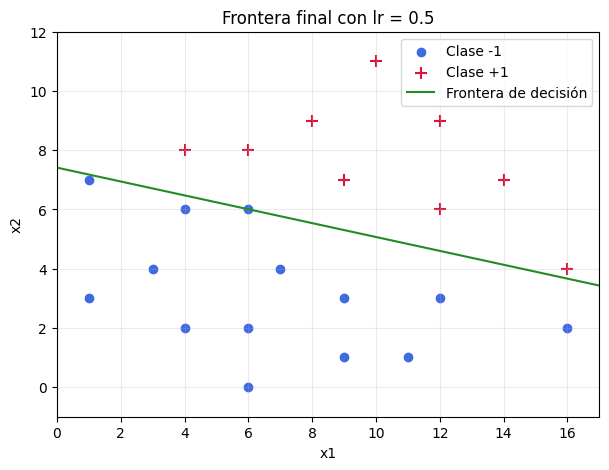

In [11]:
perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

**Pregunta guía: ¿La frontera final separa correctamente las clases? ¿Qué diferencias hay respecto a la inicial?**

Sí, la frontera final deja los puntos de cada clase a lados diferentes. Al principio, con los pesos aleatorios, el modelo cometía 9 errores; después del entrenamiento clasificó correctamente los **23 puntos**. La posición y la inclinación de la recta cambiaron gracias a las correcciones de los pesos.

### Resultados de la fase 5

Con `lr = 0.5` el perceptrón logró clasificar correctamente los **23 puntos** de entrenamiento. Frente a la recta inicial, la frontera final se ajustó a los datos después de las actualizaciones de pesos.

---
## Fase 6. Predicción con Nuevas Instancias

### Actividad 6.a — Clasificación de nuevas instancias

Probamos los tres puntos que indica la guía: `[5, 5]`, `[10, 6]` y `[6, 10]`. Como `perceptron_compute()` recibe un solo punto, recorremos la lista y obtenemos una predicción por cada uno.

In [12]:
X_test = [[5, 5], [10, 6], [6, 10]]
y_test = []

print("Instancia   | Salida predicha")
print("-----------------------------")
for punto in X_test:
    salida = perceptron_compute(punto, final_w)
    y_test.append(salida)
    print(str(punto).ljust(11), "|", "+1" if salida == 1 else "-1")

Instancia   | Salida predicha
-----------------------------
[5, 5]      | -1
[10, 6]     | +1
[6, 10]     | +1


**Pregunta guía: ¿Las predicciones son coherentes con la ubicación visual de los puntos respecto a la frontera?**

Sí. El punto **[5, 5]** quedó clasificado como **-1**, mientras que **[10, 6]** y **[6, 10]** fueron clasificados como **+1**. Esos resultados son coherentes con los lados de la frontera aprendida en la gráfica.

### Actividad 6.b — Dataset extendido

Agregamos los tres puntos y sus clases predichas a copias de las listas originales. Luego mostramos la frontera sobre el dataset extendido.

Instancias originales: 23
Instancias del dataset extendido: 26


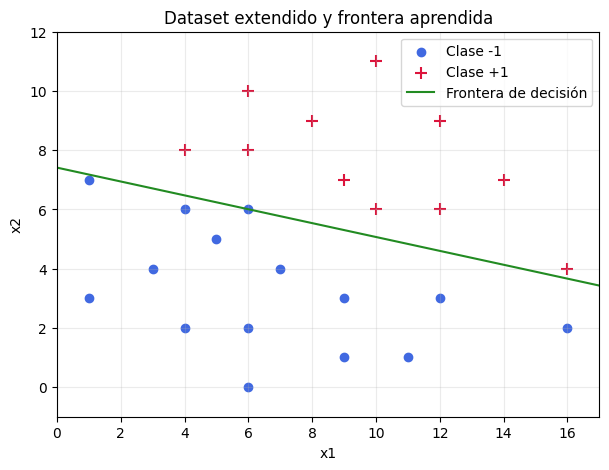

In [13]:
X_extended = [punto.copy() for punto in X]
y_extended = y.copy()

for i in range(len(X_test)):
    X_extended.append(X_test[i].copy())
    y_extended.append(y_test[i])

print("Instancias originales:", len(X))
print("Instancias del dataset extendido:", len(X_extended))
perceptron_plot(X_extended, y_extended, final_w, "Dataset extendido y frontera aprendida")

**Pregunta guía: ¿Las nuevas instancias quedaron en la región esperada? ¿Alguna parece discutible?**

Las tres quedaron en el lado de la recta que corresponde a su predicción. El punto **[10, 6]** está relativamente cerca de la frontera, así que su clasificación podría ser más sensible a cambios en los pesos que la del punto **[6, 10]**. Con la frontera entrenada en esta práctica, su salida sigue siendo +1.

---
## Fase 7. Evolución de la Frontera de Decisión

### Actividad 7.a — Seis estados del entrenamiento

Observamos la posición de la recta al inicio, al 20 %, 40 %, 60 % y 80 % del entrenamiento, y al final. Para eso usamos las copias de pesos que guardamos en `W_values`.

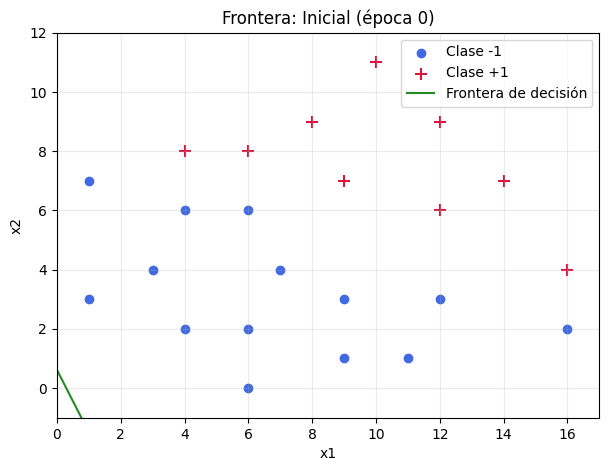

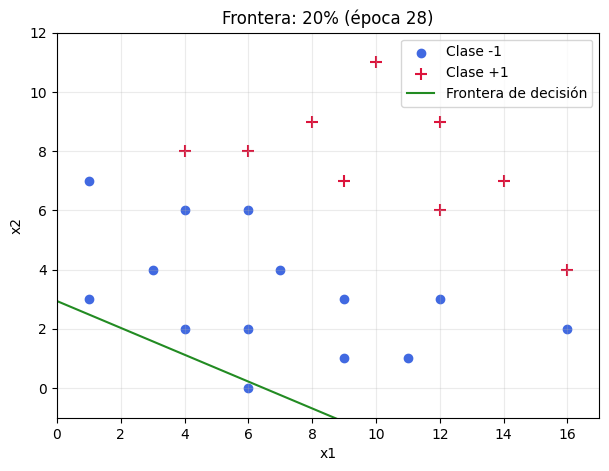

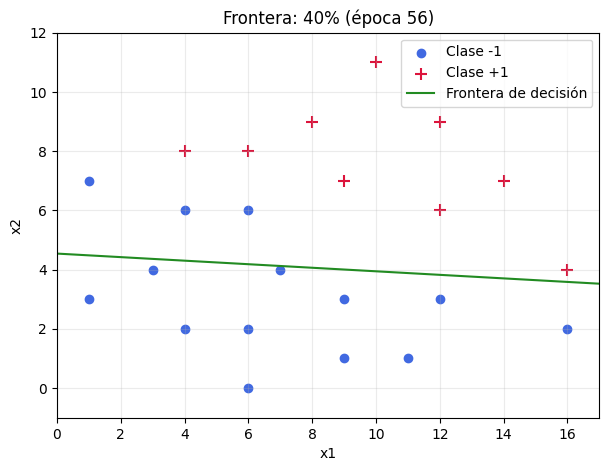

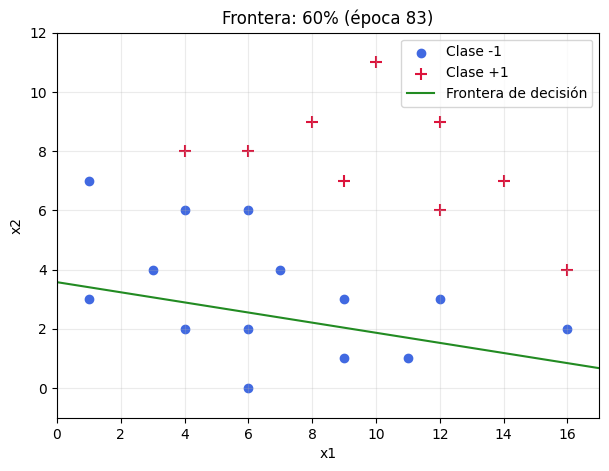

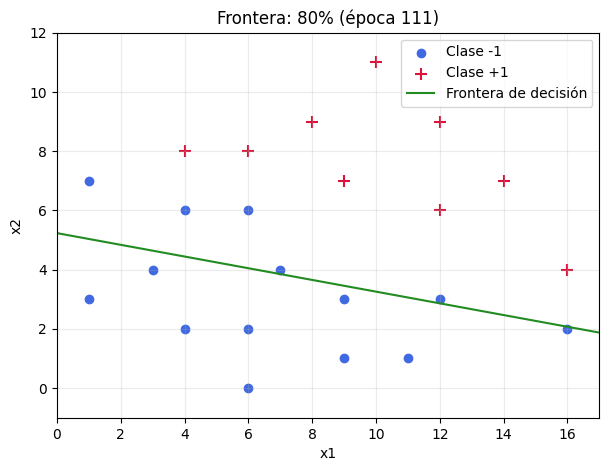

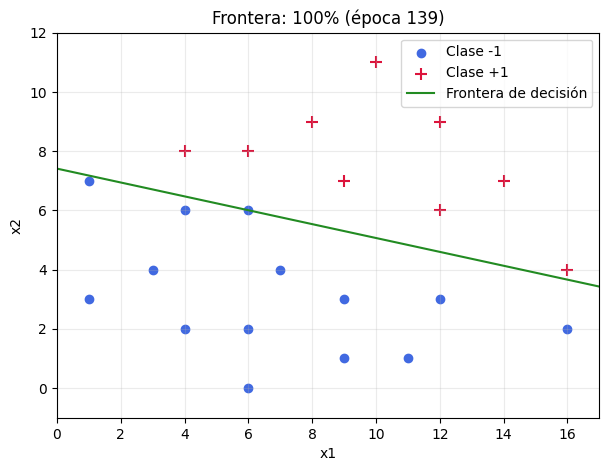

In [14]:
# Estado inicial y cinco momentos del entrenamiento con lr = 0.5
estados = [("Inicial", 0, w_initial.copy())]

for porcentaje in [20, 40, 60, 80, 100]:
    epoca_elegida = max(1, round(epochs * porcentaje / 100))
    estados.append((str(porcentaje) + "%", epoca_elegida, W_values[epoca_elegida - 1]))

# Si el entrenamiento durara menos de seis épocas, solo mostraríamos
# los estados disponibles sin repetir la misma época.
estados_unicos = []
epocas_vistas = []
for nombre, epoca_elegida, pesos_elegidos in estados:
    if epoca_elegida not in epocas_vistas:
        estados_unicos.append((nombre, epoca_elegida, pesos_elegidos))
        epocas_vistas.append(epoca_elegida)

for nombre, epoca_elegida, pesos_elegidos in estados_unicos:
    perceptron_plot(X, y, pesos_elegidos, "Frontera: " + nombre + " (época " + str(epoca_elegida) + ")")

**Pregunta guía: ¿Qué ocurre con la frontera a medida que cambian los pesos? ¿El cambio parece estable o brusco?**

La recta se va moviendo y girando mientras el modelo corrige sus errores. Los cambios no son perfectamente suaves: en algunos momentos la posición varía bastante, porque cada corrección afecta a los pesos. Al final la recta queda ubicada de manera que separa los dos grupos.

### Actividad 7.b — Interpretación geométrica

Comparamos la pendiente y la posición de la recta a partir de los pesos obtenidos.

In [15]:
print("Pesos iniciales:", [round(v, 4) for v in w_initial])
print("Pesos finales:", [round(v, 4) for v in final_w])

if final_w[2] != 0:
    pendiente = -final_w[1] / final_w[2]
    corte = -final_w[0] / final_w[2]
    print("Pendiente final de la recta:", round(pendiente, 4))
    print("Corte final con el eje x2:", round(corte, 4))

Pesos iniciales: [0.1394, -0.475, -0.225]
Pesos finales: [-79.8606, 2.525, 10.775]
Pendiente final de la recta: -0.2343
Corte final con el eje x2: 7.4116


**Pregunta guía: ¿Qué peso influye más en la inclinación? ¿Qué papel cumple el bias?**

La inclinación se determina por la relación entre `w1` y `w2`, ya que la pendiente es **`-w1 / w2`**. No depende solamente de uno de esos pesos. El bias `w0` ayuda a desplazar la recta sin cambiar esa pendiente cuando los otros dos pesos se mantienen fijos.

---
## Fase 8. Evolución del Error

### Actividad 8.a — Gráfica del error

Creamos la función `plot_error(E_values, title)` para representar la tasa de error de cada época.

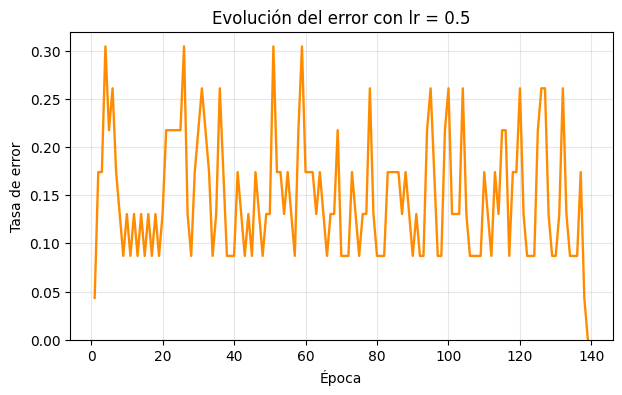

In [16]:
def plot_error(E_values, title):
    epocas_grafica = list(range(1, len(E_values) + 1))
    plt.figure(figsize=(7, 4))
    plt.plot(epocas_grafica, E_values, color="darkorange", linewidth=1.7)
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Tasa de error")
    plt.grid(alpha=0.3)
    plt.ylim(bottom=0)
    plt.show()

plot_error(E_values, "Evolución del error con lr = 0.5")

**Pregunta guía: ¿El error disminuye continuamente? Si no, ¿por qué puede aumentar o mantenerse igual?**

No disminuye de manera continua. La gráfica tiene subidas y bajadas porque una corrección puede ayudar a clasificar algunos puntos y, al mismo tiempo, hacer que otros queden momentáneamente del lado incorrecto. Lo importante es que el entrenamiento terminó con una época sin errores.

### Actividad 8.b — Análisis de convergencia

Revisamos los valores del comienzo y del final para comprobar cómo cambió el error.

In [17]:
print("Primeras cinco tasas de error:", [round(e, 4) for e in E_values[:5]])
print("Últimas cinco tasas de error:", [round(e, 4) for e in E_values[-5:]])
print("Error de la última época:", E_values[-1])

Primeras cinco tasas de error: [0.0435, 0.1739, 0.1739, 0.3043, 0.2174]
Últimas cinco tasas de error: [0.087, 0.087, 0.1739, 0.0435, 0.0]
Error de la última época: 0.0


**Pregunta guía: ¿Qué significa que el error final sea cero? ¿El modelo es perfecto con cualquier dato futuro?**

Quiere decir que el perceptrón clasificó correctamente todos los puntos del entrenamiento en su última época. Eso no lo convierte en un modelo perfecto para cualquier dato nuevo, porque solo aprendió una recta a partir de estos ejemplos y otros puntos podrían comportarse de forma diferente.

### Resultados de la fase 8

La evolución del error no es necesariamente uniforme durante las épocas. En nuestro entrenamiento, el último valor fue **0.0**, lo que confirma que se llegó a una época sin errores de clasificación en los datos utilizados.

---
## Fase 9. Comparación de Tasas de Aprendizaje

### Actividad 9.a — Entrenamiento comparativo

Repetimos el entrenamiento con **0.3, 0.5 y 0.8**. Para que la comparación sea justa, usamos el mismo vector de pesos iniciales y un máximo de 1000 épocas en los tres casos.

In [18]:
tasas = [0.3, 0.5, 0.8]
resultados = {}

for lr in tasas:
    pesos_inicio = w_initial.copy()
    pesos_finales, num_epocas, num_actualizaciones, historial_pesos, historial_error = perceptron_learning(
        X, y, pesos_inicio, lr, 1000
    )
    resultados[lr] = {
        "pesos": pesos_finales,
        "epocas": num_epocas,
        "actualizaciones": num_actualizaciones,
        "W_values": historial_pesos,
        "E_values": historial_error
    }
    print("Tasa:", lr,
          "| Épocas:", num_epocas,
          "| Actualizaciones:", num_actualizaciones,
          "| Error final:", round(historial_error[-1], 4))

Tasa: 0.3 | Épocas: 143 | Actualizaciones: 443 | Error final: 0.0
Tasa: 0.5 | Épocas: 139 | Actualizaciones: 474 | Error final: 0.0
Tasa: 0.8 | Épocas: 77 | Actualizaciones: 276 | Error final: 0.0


**Pregunta guía: ¿Por qué no sería justo comparar tasas con pesos iniciales diferentes?**

Porque las diferencias podrían deberse a la posición inicial de la recta y no a la tasa de aprendizaje. Si empezamos con los mismos pesos, podemos comparar mejor cómo influye cada tasa en las correcciones y en el tiempo que tarda en converger.

### Actividad 9.b — Gráficas comparativas

Para cada tasa generamos seis gráficas de la frontera (incluido el estado inicial) y una gráfica de error. Así se puede observar el comportamiento completo de los tres entrenamientos.


EVOLUCIÓN DE LA FRONTERA CON lr = 0.3


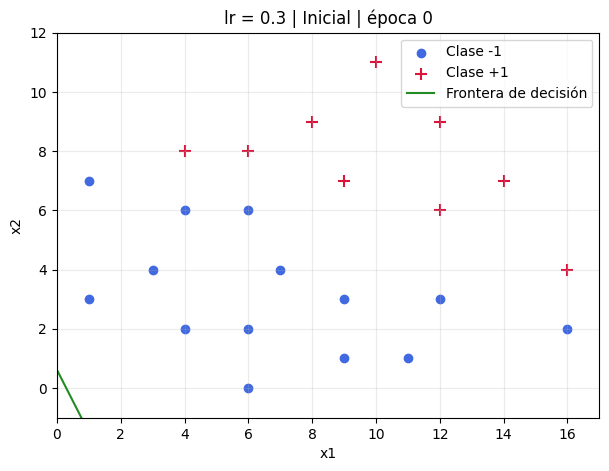

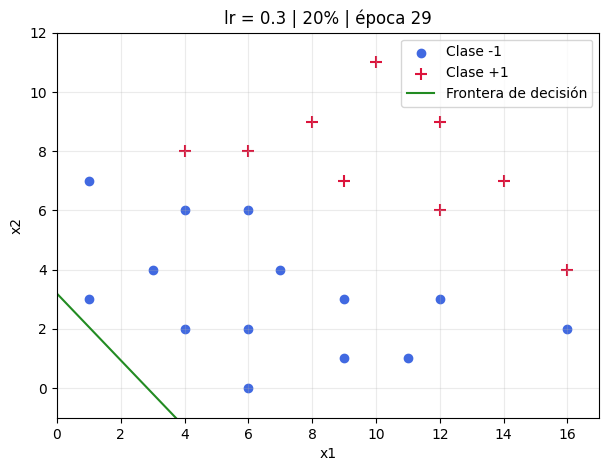

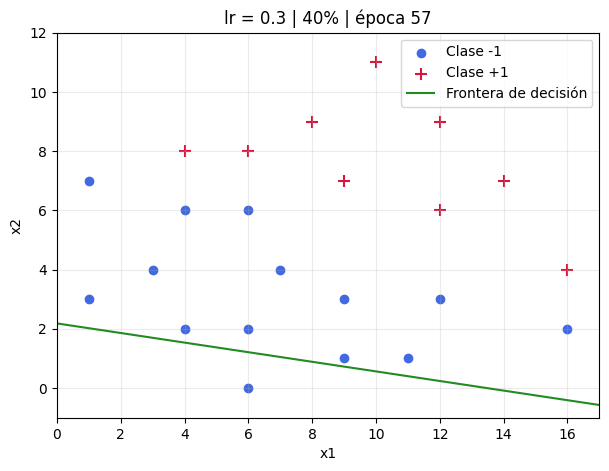

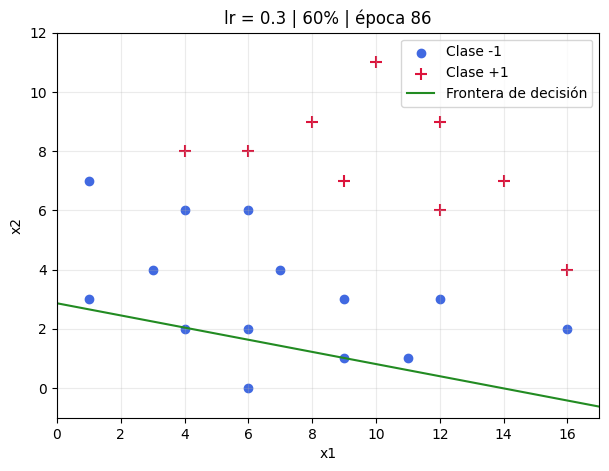

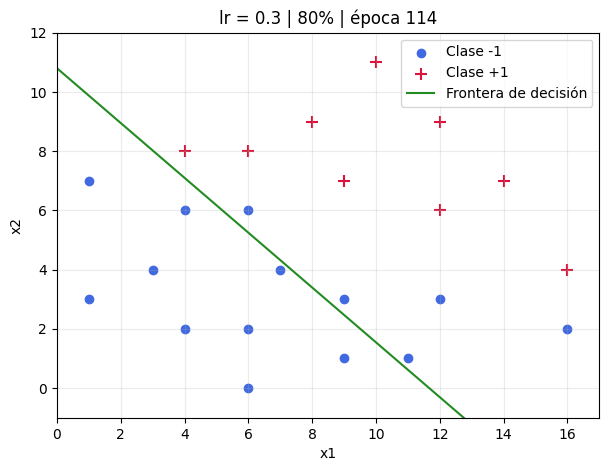

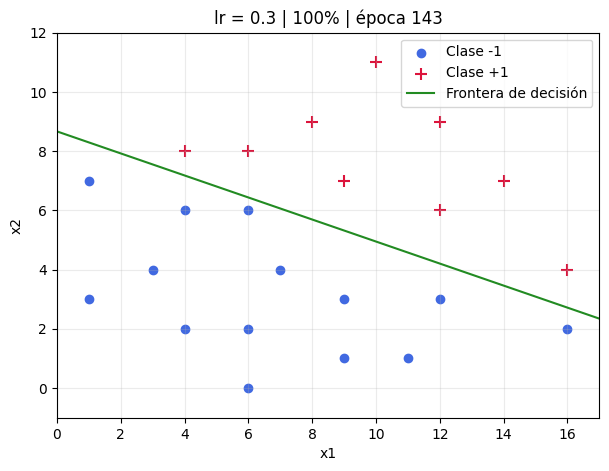

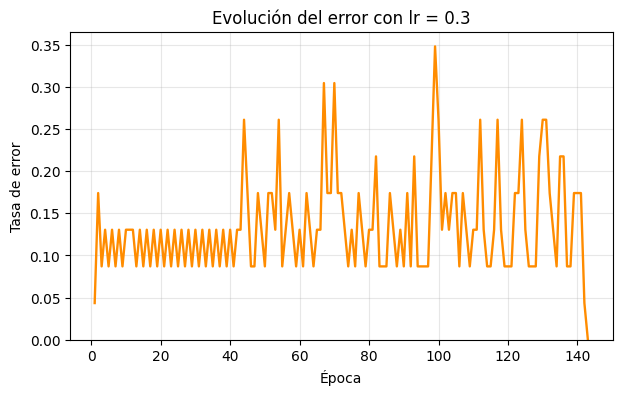


EVOLUCIÓN DE LA FRONTERA CON lr = 0.5


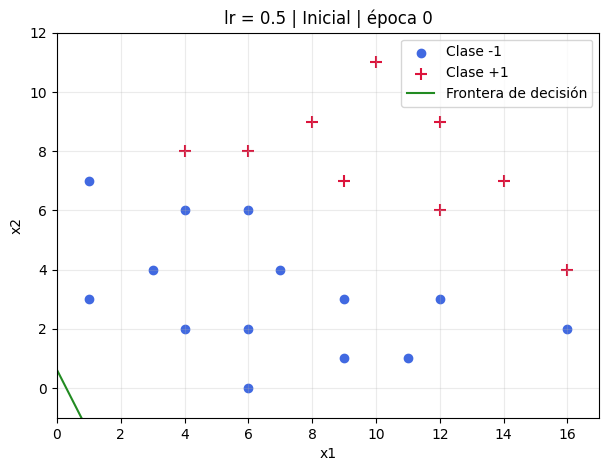

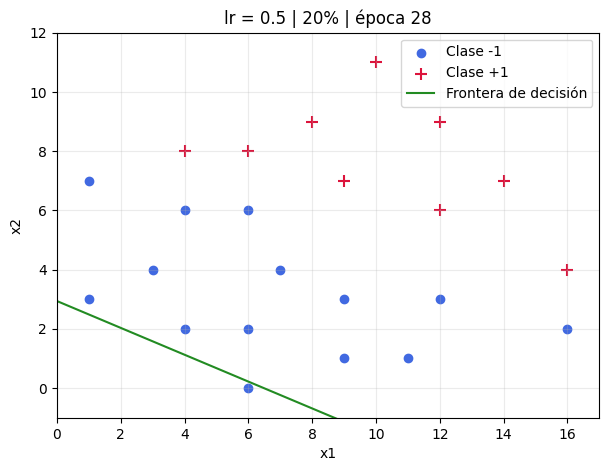

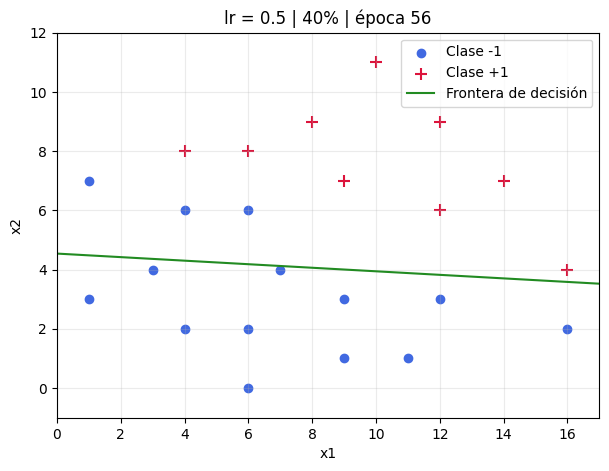

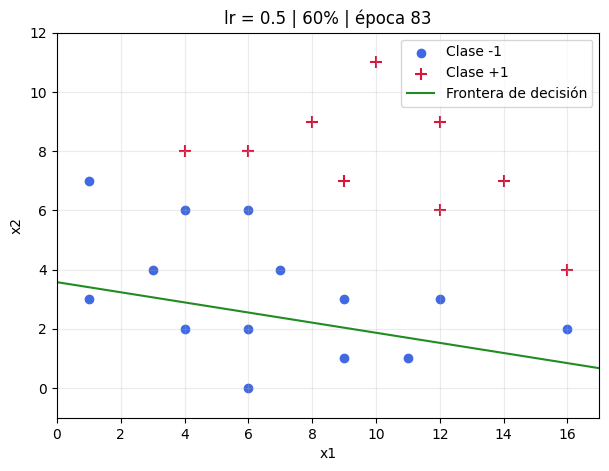

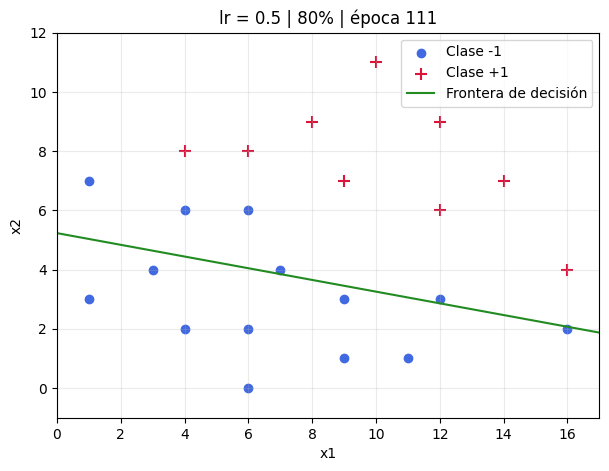

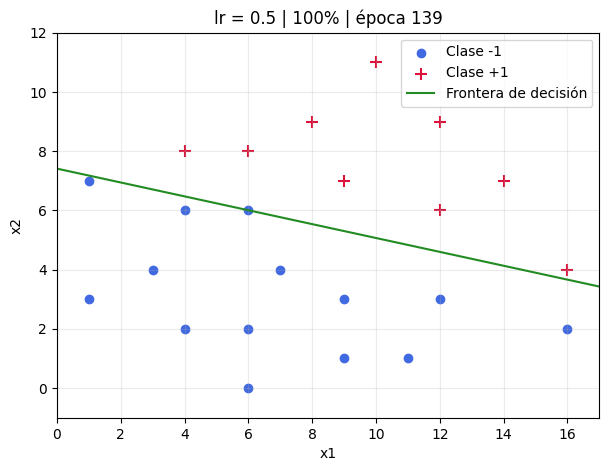

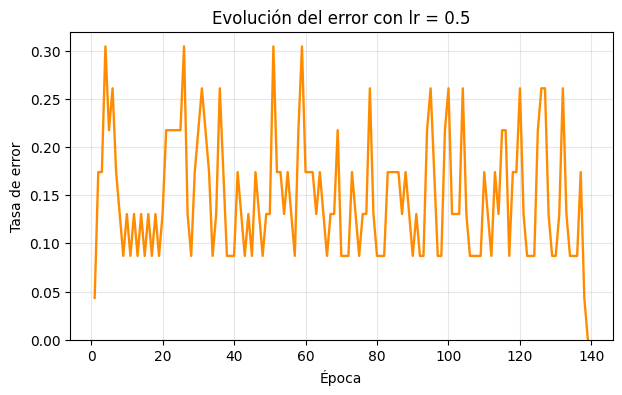


EVOLUCIÓN DE LA FRONTERA CON lr = 0.8


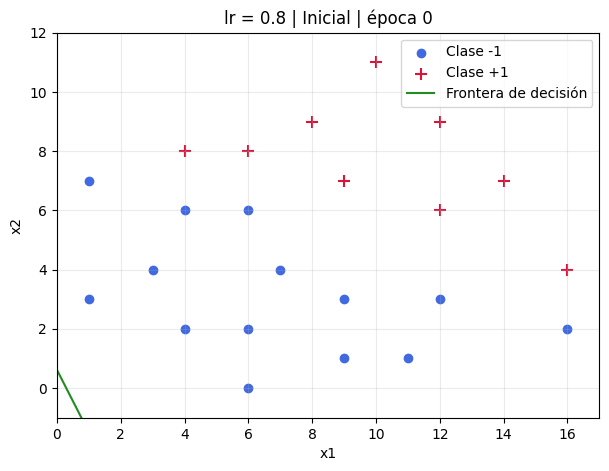

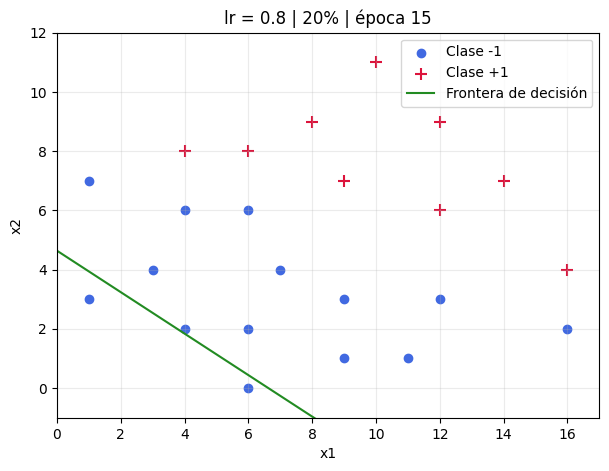

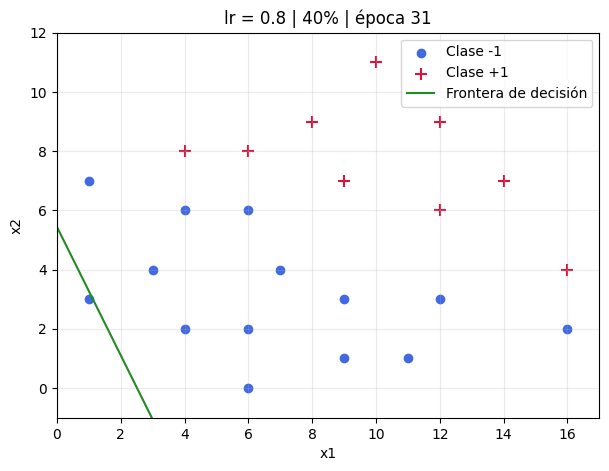

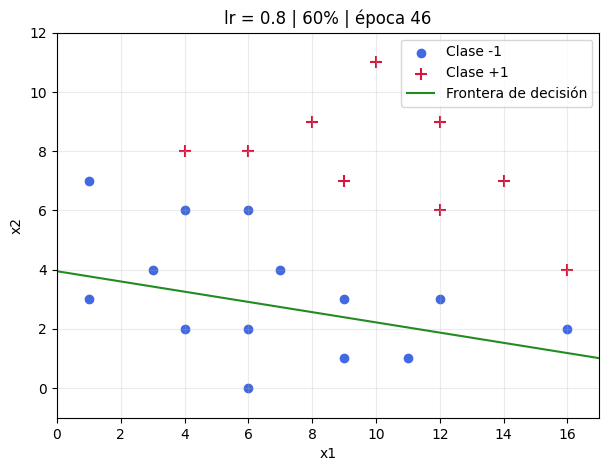

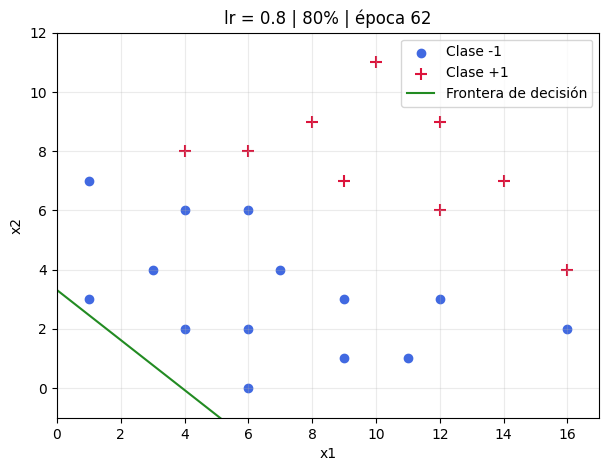

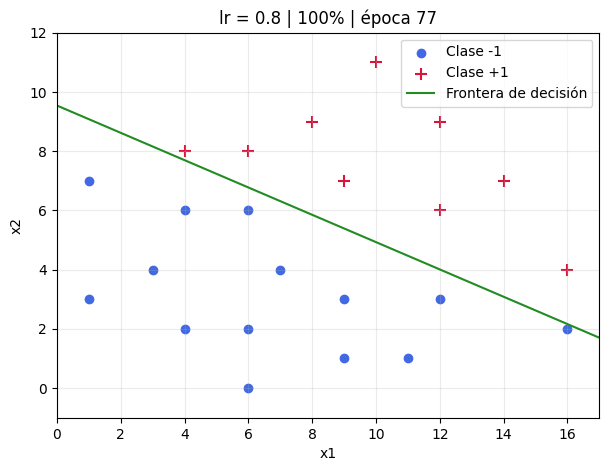

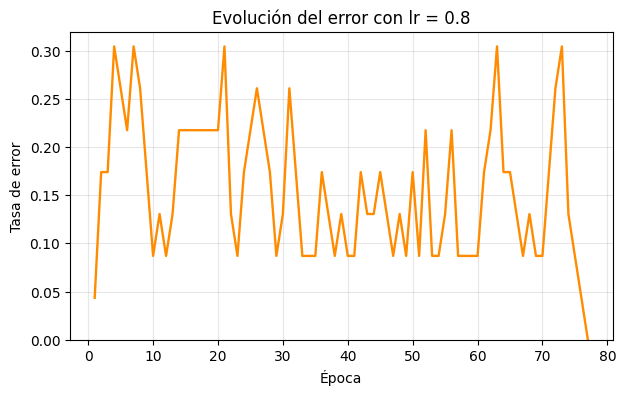

In [19]:
for lr in tasas:
    datos = resultados[lr]
    total_epocas = datos["epocas"]
    historial = datos["W_values"]

    print("\nEVOLUCIÓN DE LA FRONTERA CON lr =", lr)
    momentos = [("Inicial", 0, w_initial.copy())]
    for porcentaje in [20, 40, 60, 80, 100]:
        epoca_elegida = max(1, round(total_epocas * porcentaje / 100))
        momentos.append((str(porcentaje) + "%", epoca_elegida, historial[epoca_elegida - 1]))

    epocas_vistas = []
    for nombre, epoca_elegida, pesos_elegidos in momentos:
        if epoca_elegida not in epocas_vistas:
            titulo = "lr = " + str(lr) + " | " + nombre + " | época " + str(epoca_elegida)
            perceptron_plot(X, y, pesos_elegidos, titulo)
            epocas_vistas.append(epoca_elegida)

    plot_error(datos["E_values"], "Evolución del error con lr = " + str(lr))

**Pregunta guía: ¿Qué tasa convergió con menos épocas? ¿Eso significa que es necesariamente la mejor?**

En nuestro experimento, **lr = 0.8** llegó a cero errores con **77 épocas**, mientras que **lr = 0.5** necesitó **139** y **lr = 0.3** necesitó **143**. La tasa 0.8 fue la más rápida en este conjunto de puntos, pero no podemos afirmar que siempre será la mejor: el resultado también depende del dataset, del orden de los ejemplos y de los pesos iniciales.

**Nota sobre la comparación:** los resultados de este notebook pueden ser distintos a los del notebook de Ismael porque las condiciones iniciales del entrenamiento no fueron idénticas. En los tres experimentos de esta fase sí utilizamos los **mismos pesos iniciales**, tal como pide la guía.

### Actividad 9.c — Tabla comparativa

Resumimos los tres entrenamientos con sus épocas, actualizaciones, error final y pesos finales.

In [20]:
print("lr   | Épocas | Actualizaciones | Error final | Pesos finales")
print("-" * 85)

for lr in tasas:
    r = resultados[lr]
    pesos_txt = str([round(valor, 4) for valor in r["pesos"]])
    print(f"{lr:<4} | {r['epocas']:<6} | {r['actualizaciones']:<15} | "
          f"{r['E_values'][-1]:<11.4f} | {pesos_txt}")

lr   | Épocas | Actualizaciones | Error final | Pesos finales
-------------------------------------------------------------------------------------
0.3  | 143    | 443             | 0.0000      | [-44.8606, 1.925, 5.175]
0.5  | 139    | 474             | 0.0000      | [-79.8606, 2.525, 10.775]
0.8  | 77     | 276             | 0.0000      | [-89.4606, 4.325, 9.375]


**Pregunta guía: ¿Los pesos finales son iguales para todas las tasas? Si son diferentes, ¿por qué pueden clasificar bien?**

Los pesos finales son diferentes. Esto sucede porque cada tasa modifica los pesos con pasos de distinto tamaño. Aun así, las tres combinaciones consiguen una recta que separa las clases, por lo que pueden alcanzar cero errores sin llegar exactamente a los mismos valores.

---
## Resultados obtenidos

- Trabajamos con **23 instancias**, dos variables de entrada y dos clases: 14 puntos de clase -1 y 9 de clase +1.
- Implementamos manualmente el perceptrón, incluyendo la función escalón bipolar, la suma ponderada y la actualización de los tres pesos.
- Con **lr = 0.5**, el modelo convergió en **139 épocas** y realizó **474 actualizaciones**, con error final **0** en el dataset de entrenamiento.
- Los puntos nuevos obtuvieron las siguientes predicciones: **[5, 5] → -1**, **[10, 6] → +1** y **[6, 10] → +1**.
- En la comparación de tasas, **lr = 0.8** convergió en menos épocas para estos datos y los mismos pesos iniciales. Todas las tasas probadas terminaron sin errores de entrenamiento.

## Conclusiones

**Mauricio Jácome**  
En esta práctica entendí mejor cómo aprende un perceptrón. Al principio la recta no separaba correctamente los puntos, pero al actualizar los pesos fue cambiando hasta conseguir cero errores. Me pareció útil ver las gráficas porque así se entiende para qué sirven los pesos y el bias, más allá de las fórmulas.

**Ismael Cornejo**  
Al comparar las tasas de aprendizaje observé que no todas necesitan la misma cantidad de épocas para llegar al resultado. En nuestro caso, la tasa 0.8 fue más rápida, aunque las tres lograron separar los datos. Esto me permitió comprender que la tasa de aprendizaje influye en el proceso de entrenamiento, pero también importa comprobar los resultados y no quedarse solo con la velocidad.

## Referencias bibliográficas

1. Rosenblatt, F. (1958). *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*. Psychological Review, 65(6), 386–408.
2. McCulloch, W. S., & Pitts, W. (1943). *A Logical Calculus of the Ideas Immanent in Nervous Activity*. Bulletin of Mathematical Biophysics, 5, 115–133.
3. Ortega Martínez, H. (2019). *Machine Learning Workout: with exercises and practicals in MATLAB*. Editorial Abya-Yala / Universidad Politécnica Salesiana. https://dspace.ups.edu.ec/handle/123456789/19046
4. Universidad Politécnica Salesiana. *Guía de Práctica de Laboratorio 03: El Perceptrón*, asignatura Inteligencia Artificial (documento proporcionado en clase).

---
## Comprobación final de la práctica

Antes de entregar verificamos que se incluyan las nueve fases, que las funciones manuales estén definidas, que el conjunto de datos tenga la cantidad esperada y que los entrenamientos con las tres tasas finalicen correctamente. Esta celda muestra el resumen de la ejecución.

In [21]:
# Comprobación del dataset y los experimentos del grupo
assert len(X) == 23 and len(y) == 23
assert y.count(-1) == 14 and y.count(1) == 9
assert len(X_test) == 3 and len(X_extended) == 26
assert set(resultados.keys()) == {0.3, 0.5, 0.8}
assert len(W_values) == len(E_values) == epochs
assert E_values[-1] == 0

print("Integrantes: Mauricio Jácome e Ismael Cornejo")
print("Dataset:", len(X), "instancias |", len(X_extended), "con las predicciones")
print("Tasas comparadas:", tasas)
print("Verificación final: se cumplieron las comprobaciones sin errores.")

Integrantes: Mauricio Jácome e Ismael Cornejo
Dataset: 23 instancias | 26 con las predicciones
Tasas comparadas: [0.3, 0.5, 0.8]
Verificación final: se cumplieron las comprobaciones sin errores.
